# Оценка checkpoint-147871 на held-out test

Этот ноутбук проверяет **предыдущую обученную модель** из `artifacts/experiments/baseline_001/checkpoint-147871`: 10 000 примеров, seed 42, один greedy-кандидат на вопрос. Готовые веса и BPE загружаются локально; обучение здесь не запускается.

Сначала воспроизводится прежнее разбиение исходного `train`: **80% train / 10% val / 10% test, seed 42**. Затем из внутренней test-части выбираются 10 000 случайных строк с seed 42. Комментарии удаляются только в этих 10 000 эталонах. Отбор не использует длину, правильность или исполнимость ответа. Это разбиение по строкам: одинаковые вопросы могут встретиться в разных частях.

Официальный `test` из 1 919 вопросов не содержит эталонного `code`, поэтому он не используется для pass@1. Здесь измеряется локальное совпадение результатов `solve()` с эталоном на внутренней отложенной части, а не результат скрытого checker соревнования.

По умолчанию `RUN_EVALUATION = False`: ноутбук читает последний завершённый запуск с подходящими checkpoint / размером / seed. Для новой оценки включите флаг; автоматически создастся отдельная папка в `artifacts/evaluations/`. Чтобы открыть конкретный запуск, укажите `RESULT_DIR`.

`DATA_DIR=None` автоматически ищет `data/tinysms_qa_12m_ssh`, затем `data/tinysms_qa_12m`. Можно указать локальный DatasetDict, сохранённый через `save_to_disk()`, с полным исходным train в том же порядке, что при обучении, и официальным test без эталонов (столбец `code` отсутствует или целиком `null`). Уже разбитый DatasetDict с val / validation или с эталонами в test будет отклонён: повторно разбивать его train небезопасно для честной оценки. Данные с Hub не скачиваются.

In [1]:
from pathlib import Path

RUN_EVALUATION = False
CHECKPOINT = Path("artifacts/experiments/baseline_001/checkpoint-147871")
DATA_DIR = None
RESULT_DIR = None  # Например Path("artifacts/evaluations/checkpoint-147871_test10000_seed42_...")
OUTPUT_DIR = None  # Для нового запуска: None = уникальная новая папка; существующая папка запрещена.
TOKENIZER_PATH = None  # По умолчанию tokenizer.json рядом с checkpoint / в папке обучения.

SAMPLE_SIZE = 10_000
SAMPLE_SEED = 42  # Seed разбиения train/val/test всегда остаётся 42.
BATCH_SIZE = 64
DEVICE = "cuda:0"
PRECISION = "fp16"  # "bf16" для поддерживающей GPU; "no" для CPU/MPS.
MAX_SOURCE_LENGTH = 256
MAX_NEW_TOKENS = 256
EVALUATION_WORKERS = 8
TIMEOUT_SECONDS = 2.0

In [2]:
import json
import math
import sys
from html import escape
from IPython.display import Code, HTML, Image, Markdown, display

# Ноутбук можно открыть из корня проекта или вложенной папки.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "evaluate_checkpoint.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Откройте ноутбук в проекте nlp-hw2 рядом с evaluate_checkpoint.py.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

def project_path(value):
    if value is None:
        return None
    path = Path(value).expanduser()
    return path if path.is_absolute() else PROJECT_ROOT / path

from evaluate_checkpoint import (
    CheckpointEvaluationConfig, find_latest_result, load_saved_result, run_evaluation,
)

config = CheckpointEvaluationConfig(
    checkpoint=project_path(CHECKPOINT), data_dir=project_path(DATA_DIR),
    output_dir=project_path(OUTPUT_DIR), tokenizer_path=project_path(TOKENIZER_PATH),
    sample_size=SAMPLE_SIZE, seed=SAMPLE_SEED, batch_size=BATCH_SIZE,
    device=DEVICE, precision=PRECISION, max_source_length=MAX_SOURCE_LENGTH,
    max_new_tokens=MAX_NEW_TOKENS, workers=EVALUATION_WORKERS,
    timeout_seconds=TIMEOUT_SECONDS,
)
if RUN_EVALUATION:
    result_dir = run_evaluation(config)
elif RESULT_DIR is not None:
    result_dir = project_path(RESULT_DIR)
else:
    result_dir = find_latest_result(checkpoint=CHECKPOINT, sample_size=SAMPLE_SIZE,
                                    seed=SAMPLE_SEED, results_root=PROJECT_ROOT / "artifacts/evaluations")

result = load_saved_result(result_dir) if result_dir is not None else None
if result is None:
    display(Markdown("**Готовая оценка ещё не найдена.** Укажите RESULT_DIR или включите RUN_EVALUATION для нового запуска."))
else:
    manifest = json.loads((result_dir / "sample_manifest.json").read_text(encoding="utf-8"))
    metrics = result.metrics
    display(Markdown(f"**Загружен завершённый результат:** `{result_dir}`"))
    display(Markdown(
        f"Исходный train: **{manifest['raw_train_size']:,}** строк; "
        f"held-out test: **{manifest['heldout_size']:,}**; "
        f"выборка: **{manifest['sample_size']:,}** "
        f"({manifest['sample_fraction_of_heldout']:.2%} от held-out test). "
        f"Seed разбиения: **{manifest['split_seed']}**, seed выборки: **{manifest['sample_seed']}**."
    ))

Generating train split: 0 examples [00:00, ? examples/s]

**Загружен завершённый результат:** `/Users/artyom-step/nlp-hw2/artifacts/evaluations/checkpoint-147871_test10000_seed42_20261013_v3`

Исходный train: **11,838,003** строк; held-out test: **1,183,800**; выборка: **10,000** (0.84% от held-out test). Seed разбиения: **42**, seed выборки: **42**.

## Что именно измеряется

- **pass@1** — число совпавших результатов `solve()` / число строк с исполнимым эталоном (`num_evaluated`). Генерируется один кандидат. Неисполнимые эталоны исключаются из знаменателя и отдельно учитываются в `reference_error_rate`.
- **Bad code** — доля всех 10 000 кандидатов, которые не исполнились: синтаксическая ошибка, ошибка выполнения, timeout или неподдерживаемая конструкция. **Wrong answer** — исполнившийся код с неверным результатом, делённый на число строк с исполнимым эталоном. Знаменатели этих долей различаются.
- **Coverage** — доля выборки с исполнимым эталоном. Дополнительно показывается `num_passed / SAMPLE_SIZE`, чтобы исключение эталонов было видно.
- Ограниченный runner поддерживает арифметический Python и `math`, но не файлы, сеть и произвольные imports. `unsupported_code` может означать ограничение evaluator. Для чисел используются допуски `rtol=1e-6`, `atol=1e-8`.
- Вопросы длиннее `MAX_SOURCE_LENGTH` токенов обрезаются с сохранением EOS; строки остаются в оценке. Эталонный код не обрезается. Отдельно показаны частота обрезки вопросов и достижение лимита генерации.

95% интервал Уилсона характеризует неопределённость оценки доли на этой выборке; он не учитывает возможные дубликаты / зависимость строк и сдвиг распределения официального теста.

In [3]:
def wilson_interval(successes, trials, z=1.959963984540054):
    if trials == 0:
        return None
    rate = successes / trials
    denominator = 1 + z * z / trials
    center = (rate + z * z / (2 * trials)) / denominator
    half = z * math.sqrt(rate * (1 - rate) / trials + z * z / (4 * trials * trials)) / denominator
    return max(0.0, center - half), min(1.0, center + half)

def percent(value):
    return "нет данных" if value is None else f"{value:.2%}"

if result is not None:
    interval = wilson_interval(metrics['num_passed'], metrics['num_evaluated'])
    ci_text = "нет исполнимых эталонов" if interval is None else f"[{interval[0]:.2%}, {interval[1]:.2%}]"
    rows = [
        ("Выбрано строк", f"{metrics['num_examples']:,}"),
        ("Исполнимых эталонов — знаменатель pass@1", f"{metrics['num_evaluated']:,}"),
        ("Совпало solve()", f"{metrics['num_passed']:,}"),
        ("pass@1", percent(metrics.get('pass@1'))),
        ("95% интервал Уилсона", ci_text),
        ("Совпало / все выбранные строки", percent(metrics['passed_fraction_of_all_sampled'])),
        ("Coverage эталонов", percent(metrics.get('evaluation_coverage'))),
        ("Ошибки эталонов / все строки", percent(metrics.get('reference_error_rate'))),
        ("Bad code / все строки", percent(metrics.get('bad_code_rate'))),
        ("Wrong answer / исполнимые эталоны", percent(metrics.get('wrong_answer_rate'))),
        ("Обрезанные вопросы / все строки", percent(metrics.get('source_truncated_rate'))),
        ("Достигнут лимит генерации / все строки", percent(metrics.get('hit_token_limit_rate'))),
        ("EOS / все строки", percent(metrics.get('eos_rate'))),
        ("Генерация с токенизацией и декодированием, с", f"{metrics['total_seconds']:.1f}"),
        ("Выполнение кода и сравнение, с", f"{metrics['evaluation_seconds']:.1f}"),
        ("Примеров / с (генерация)", f"{metrics['examples_per_second']:.2f}"),
        ("Устройство / точность", f"{metrics['device']} / {metrics['mixed_precision']}"),
    ]
    display(Markdown("| Метрика | Значение |\n|---|---:|\n" + "\n".join(f"| {name} | {value} |" for name, value in rows)))
    for title, key in [("Статусы предсказаний", "status_counts"), ("Статусы эталонов", "reference_status_counts")]:
        display(Markdown(f"**{title}**"))
        display(Markdown("| Статус | Строк |\n|---|---:|\n" + "\n".join(
            f"| {status} | {count:,} |" for status, count in sorted(metrics[key].items(), key=lambda item: -item[1]))))

| Метрика | Значение |
|---|---:|
| Выбрано строк | 10,000 |
| Исполнимых эталонов — знаменатель pass@1 | 9,929 |
| Совпало solve() | 6,452 |
| pass@1 | 64.98% |
| 95% интервал Уилсона | [64.04%, 65.91%] |
| Совпало / все выбранные строки | 64.52% |
| Coverage эталонов | 99.29% |
| Ошибки эталонов / все строки | 0.71% |
| Bad code / все строки | 1.50% |
| Wrong answer / исполнимые эталоны | 33.53% |
| Обрезанные вопросы / все строки | 0.00% |
| Достигнут лимит генерации / все строки | 0.52% |
| EOS / все строки | 99.48% |
| Генерация с токенизацией и декодированием, с | 127.9 |
| Выполнение кода и сравнение, с | 63.3 |
| Примеров / с (генерация) | 78.19 |
| Устройство / точность | cuda:0 / fp16 |

**Статусы предсказаний**

| Статус | Строк |
|---|---:|
| passed | 6,452 |
| wrong_answer | 3,329 |
| runtime_error | 117 |
| ok | 69 |
| invalid_output | 17 |
| syntax_error | 13 |
| timeout | 3 |

**Статусы эталонов**

| Статус | Строк |
|---|---:|
| ok | 9,929 |
| runtime_error | 45 |
| unsupported_code | 20 |
| invalid_output | 6 |

## Качество, длины и время генерации

На графике pass@1 и Wrong answer используют исполнимые эталоны; Bad code использует всю выборку. Время батчей зависит от длины вопросов, поскольку генератор сортирует их по длине. В сохранённых файлах восстановлен исходный порядок выборки.

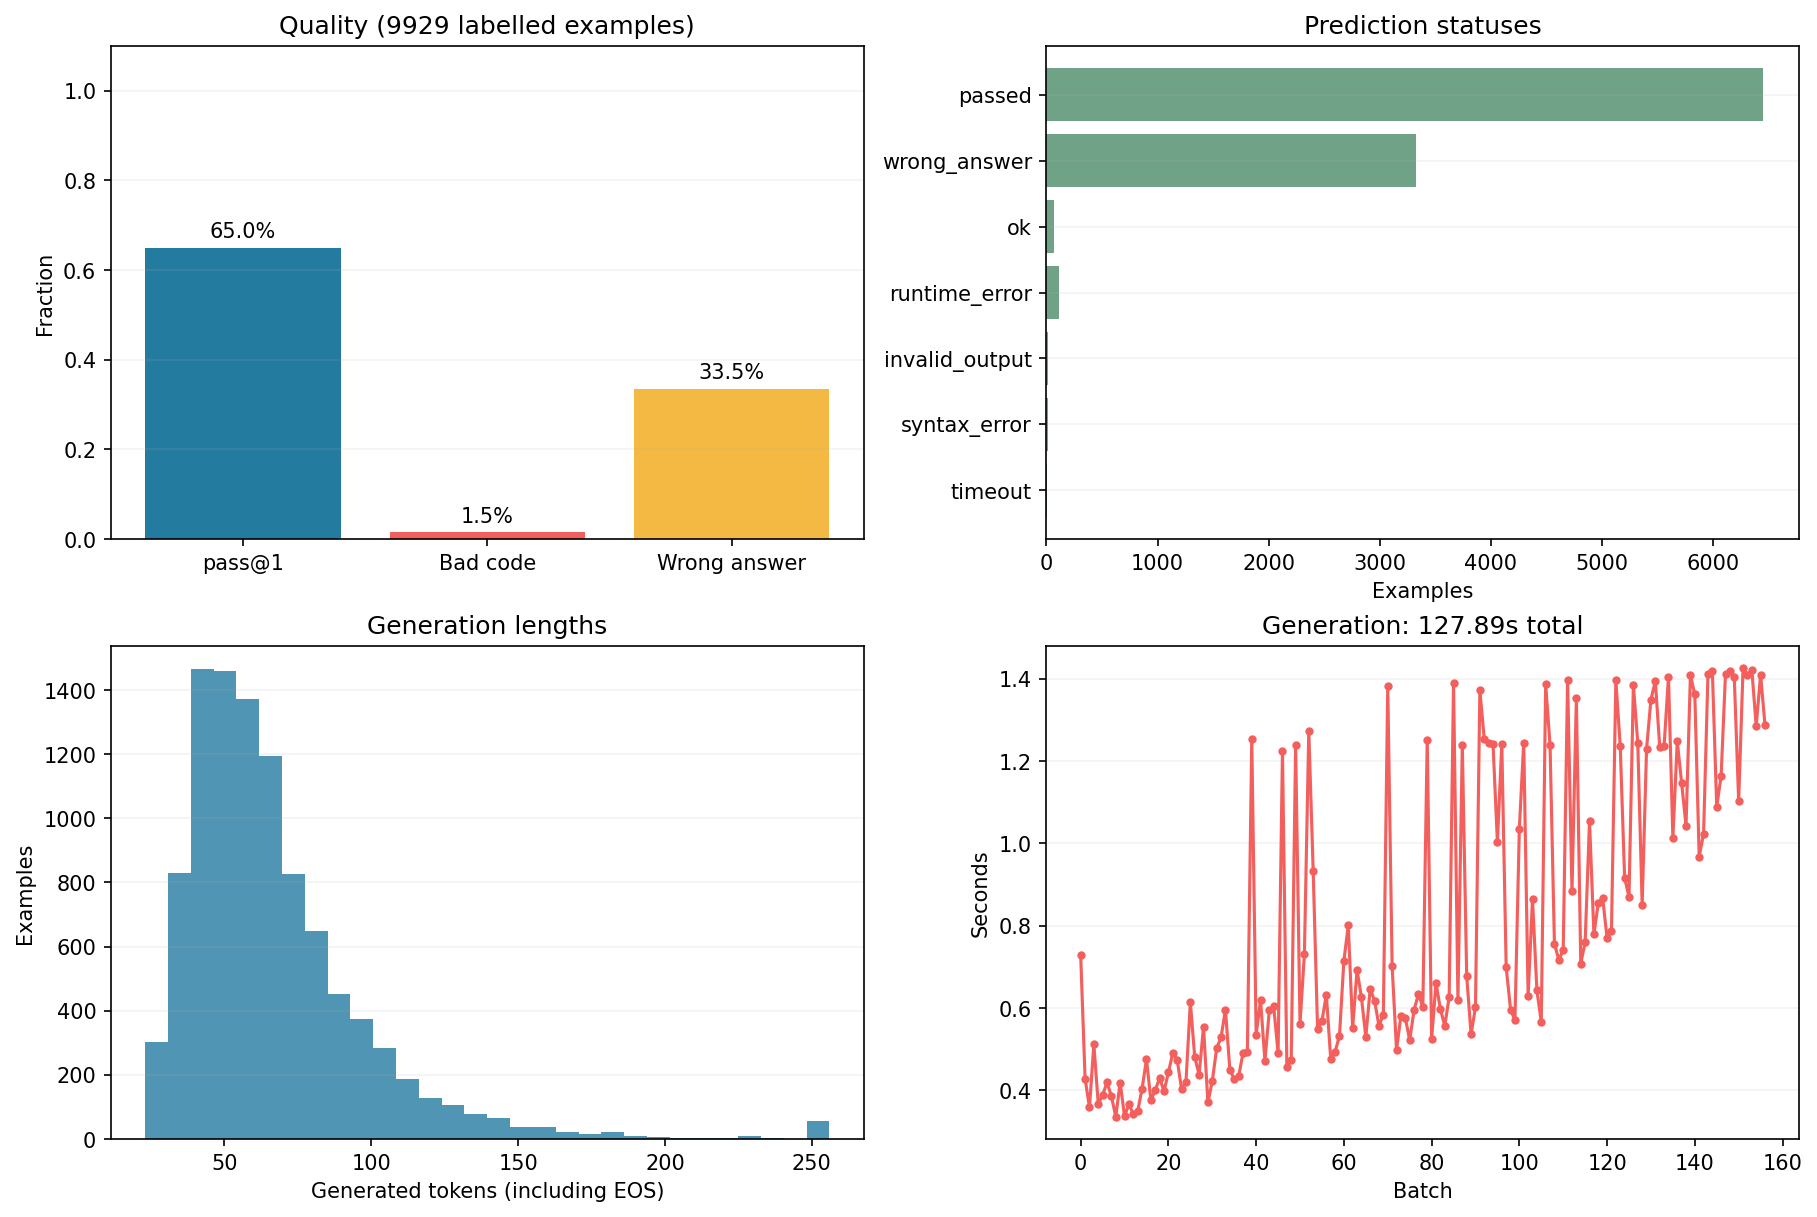

In [4]:
if result is not None:
    display(Image(filename=str(result_dir / "plots" / "evaluation.png")))

## История предыдущего обучения

Графики читаются из сохранённого `trainer_state.json` выбранного checkpoint (или `log_history.json` в папке обучения). Никакие шаги обучения не выполняются. Это loss на прежнем train / val, а не pass@1 текущего held-out test.

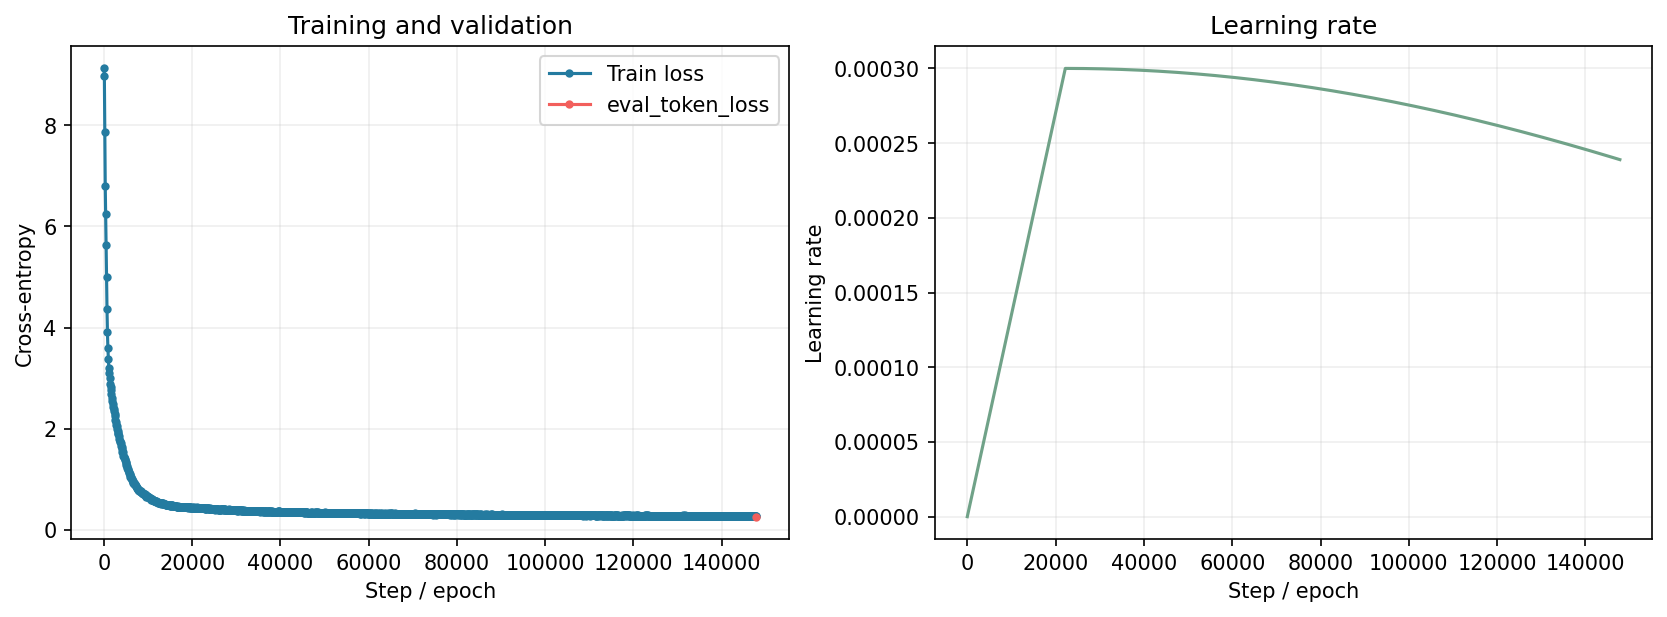

In [5]:
if result is not None:
    history_plot = result_dir / "plots" / "training.png"
    if history_plot.is_file():
        display(Image(filename=str(history_plot)))
    else:
        display(Markdown("В артефактах checkpoint нет непустой истории обучения; график loss недоступен."))

## Примеры: совпадение, неверный ответ, сломанный код

Показываются первые три строки каждой категории в исходном порядке выборки, максимум девять примеров. `source_row_index` — индекс в исходном локальном train до разбиения; `sample_row` — позиция в сохранённой выборке. Длинный код в этом просмотре ограничен 3 000 символами; полная версия остаётся в JSONL.

In [6]:
if result is not None:
    groups = {"Совпало": [], "Неверный ответ": [], "Код не исполнился": []}
    for row in result.predictions:
        group = ("Совпало" if row['passed'] is True else
                 "Неверный ответ" if row['status'] == 'wrong_answer' else
                 "Код не исполнился" if row['execution_status'] != 'ok' else None)
        if group is not None and len(groups[group]) < 3:
            groups[group].append(row)
    for label, examples in groups.items():
        display(Markdown(f"### {label}"))
        if not examples:
            display(Markdown("В этой выборке нет примеров категории."))
        for row in examples:
            display(Markdown(
                f"**sample_row={row['sample_row']}, source_row_index={row['source_row_index']}** — "
                f"`{row['status']}`, эталон: `{row['reference_status']}`"
            ))
            display(HTML("<p>" + escape(row['question']) + "</p>"))
            display(Markdown("Предсказание:"))
            display(Code((row['generated_code'] or '')[:3000], language='python'))
            display(Markdown("Эталон:"))
            display(Code((row['code'] or '')[:3000], language='python'))
            diagnostic = {key: row.get(key) for key in [
                'result_json', 'reference_result_json', 'error', 'reference_error',
                'source_tokens', 'source_truncated', 'generated_tokens', 'hit_token_limit',
            ]}
            display(Code(json.dumps(diagnostic, ensure_ascii=False, indent=2), language='json'))

### Совпало

**sample_row=0, source_row_index=9081016** — `passed`, эталон: `ok`

Предсказание:

def solve() -> int:
    marbles = 25
    marbles_given = marbles * 2
    marbles_left = marbles - marbles_given
    result = marbles_left
    return result

Эталон:

...

Предсказание:

def solve() -> int:
    davids_portraits = 50
    samantha_distance = 2
    davids_scenery_distance = davids_portraits * samantha_distance
    davids_scenery_distance_per_mile = davids_scenery_distance / samantha_distance
    davids_scenery_distance_per_mile = davids_scenery_distance_per_mile * davids_scenery_distance_per_mile
    davids_scenery_distance_per_mile = davids_scenery_distance_per_mile * samantha_distance
    davids_scenery_distance_per_mile = davids_scenery_distance_per_mile * samantha_distance
    davids_scenery_distance_per_mile = davids_scenery_distance_per_mile * davids_scenery_distance_per_mile
    davids_scenery_distance_per_mile = davids_scenery_distance_per_mile * davids_scenery_distance
    davids_scenery_distance_per_mile = davids_scenery_distance_per_mile * davids_scenery_distance
    davids_per_mile

Эталон:

def solve() -> int:
    portraits_painted = 50
    miles_samantha_ran = 2
    scenery_paintings = portraits_painted - math.ceil(miles_samantha_ran/10)
    result = scenery_paintings
    print(f'<<<{result}>>>')
    
    return result

{
  "result_json": null,
  "reference_result_json": "49",
  "error": "NameError: name 'davids_per_mile' is not defined",
  "reference_error": null,
  "source_tokens": 46,
  "source_truncated": false,
  "generated_tokens": 256,
  "hit_token_limit": true
}

## Сохранённые артефакты и запуск через SSH

В папке каждого запуска находятся:

- `sample/` — Dataset из выбранных 10 000 строк с очищенным эталоном и идентификаторами;
- `sample_manifest.json` — источник данных, размеры частей, seeds и правила отбора;
- `inference/predictions.jsonl`, `inference/codes.json` — полные предсказания в порядке выборки;
- `evaluation/evaluation.jsonl` — код, результаты выполнения, ошибки и статусы всех строк;
- `metrics.json`, `run.json` — метрики и параметры завершённого запуска;
- `plots/evaluation.png`, при доступной истории `plots/training.png` и `training_history.json`.

Тот же запуск без Jupyter:

```bash
python evaluate_checkpoint.py \
  --checkpoint artifacts/experiments/baseline_001/checkpoint-147871 \
  --data-dir data/tinysms_qa_12m_ssh \
  --sample-size 10000 --seed 42 \
  --batch-size 64 --device cuda:0 --precision fp16 \
  --max-source-length 256 --max-new-tokens 256 --workers 8
```

После CLI-запуска выполните ноутбук с `RUN_EVALUATION=False`, чтобы встроить готовые таблицы, графики и примеры в `.ipynb`.

In [7]:
if result is not None:
    for relative in ["sample", "sample_manifest.json", "inference/predictions.jsonl",
                     "evaluation/evaluation.jsonl", "metrics.json", "plots/evaluation.png",
                     "plots/training.png"]:
        path = result_dir / relative
        if path.exists():
            print(path)

/Users/artyom-step/nlp-hw2/artifacts/evaluations/checkpoint-147871_test10000_seed42_20261013_v3/sample
/Users/artyom-step/nlp-hw2/artifacts/evaluations/checkpoint-147871_test10000_seed42_20261013_v3/sample_manifest.json
/Users/artyom-step/nlp-hw2/artifacts/evaluations/checkpoint-147871_test10000_seed42_20261013_v3/inference/predictions.jsonl
/Users/artyom-step/nlp-hw2/artifacts/evaluations/checkpoint-147871_test10000_seed42_20261013_v3/evaluation/evaluation.jsonl
/Users/artyom-step/nlp-hw2/artifacts/evaluations/checkpoint-147871_test10000_seed42_20261013_v3/metrics.json
/Users/artyom-step/nlp-hw2/artifacts/evaluations/checkpoint-147871_test10000_seed42_20261013_v3/plots/evaluation.png
/Users/artyom-step/nlp-hw2/artifacts/evaluations/checkpoint-147871_test10000_seed42_20261013_v3/plots/training.png
